In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing import image

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
# Dataset Path

dataset_path = "/content/drive/MyDrive/ SOIL DATASET/6_Soiltypes(600)/6_Soiltypes(600)"

# Check dataset folders
print("Dataset Classes:")
print(os.listdir(dataset_path))

Dataset Classes:
['Loamy soil', 'Slit soil', 'Alluvial soil', 'Sandy soil', 'Clay soil', 'Black soil']


In [4]:
# ============================================
# Load Dataset
# ============================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Dataset loaded successfully!")

Found 3600 files belonging to 6 classes.
Using 2520 files for training.
Found 3600 files belonging to 6 classes.
Using 1080 files for validation.
Dataset loaded successfully!


In [5]:
# ============================================
# Split Validation and Test Dataset
# ============================================

# Number of batches in validation dataset
val_test_batches = tf.data.experimental.cardinality(val_test_dataset)

print("Total batches:", val_test_batches.numpy())

# Split into Validation (15%) and Test (15%)
val_dataset = val_test_dataset.take(val_test_batches // 2)
test_dataset = val_test_dataset.skip(val_test_batches // 2)

print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Total batches: 34
Validation batches: 17
Test batches: 17


In [6]:
# ============================================
# Optimize Dataset Performance
# ============================================

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)

test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

print("Dataset optimized successfully!")

Dataset optimized successfully!


In [7]:
# ============================================
# Data Augmentation
# ============================================

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    tf.keras.layers.RandomContrast(0.1)
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [8]:
# ============================================
# Load Pretrained EfficientNetB0 Model
# ============================================

from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze all pretrained layers
base_model.trainable = False

print("EfficientNetB0 loaded successfully!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!


In [9]:
# ============================================
# Build the Soil Classification Model
# ============================================

from tensorflow.keras import layers, models

model = models.Sequential([
    data_augmentation,
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dropout(0.4),

    layers.Dense(256, activation='relu'),

    layers.BatchNormalization(),

    layers.Dropout(0.3),

    layers.Dense(6, activation='softmax')
])

print("Model created successfully!")

Model created successfully!


In [10]:
# ============================================
# Compile the Model
# ============================================

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [11]:
# ============================================
# Create Callbacks
# ============================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/best_efficientnetb0_soil_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [12]:
# ============================================
# Train the Model
# ============================================

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=[
        early_stopping,
        model_checkpoint,
        reduce_lr
    ]
)

print("Model training completed successfully!")

Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6492 - loss: 1.0968
Epoch 1: val_accuracy improved from None to 0.88603, saving model to /content/drive/MyDrive/best_efficientnetb0_soil_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_efficientnetb0_soil_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 680s 4s/step - accuracy: 0.7980 - loss: 0.6132 - val_accuracy: 0.8860 - val_loss: 0.3727 - learning_rate: 0.0010
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9268 - loss: 0.2132
Epoch 2: val_accuracy improved from 0.88603 to 0.93382, saving model to /content/drive/MyDrive/best_efficientnetb0_soil_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_efficientnetb0_soil_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 282s 4s/step - accuracy: 0.9222 - loss: 0.2383 - val_accuracy: 0.9338 - val_loss: 0.2031 - learning_rate: 0.0010
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9267 - loss: 0.2218
Epoch 3: val_accurac

In [13]:
# ============================================
# Evaluate the Model
# ============================================

test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

17/17 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.9739 - loss: 0.0632

Test Loss: 0.0632
Test Accuracy: 97.39%


In [14]:
print(f"Final Training Accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")

Final Training Accuracy: 96.83%
Final Validation Accuracy: 97.61%


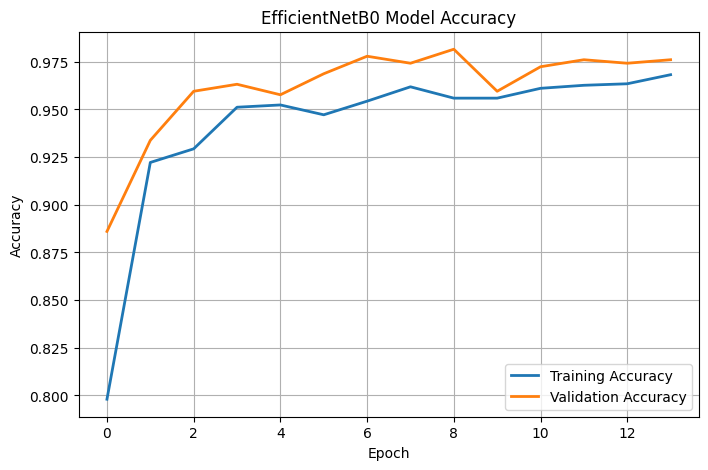

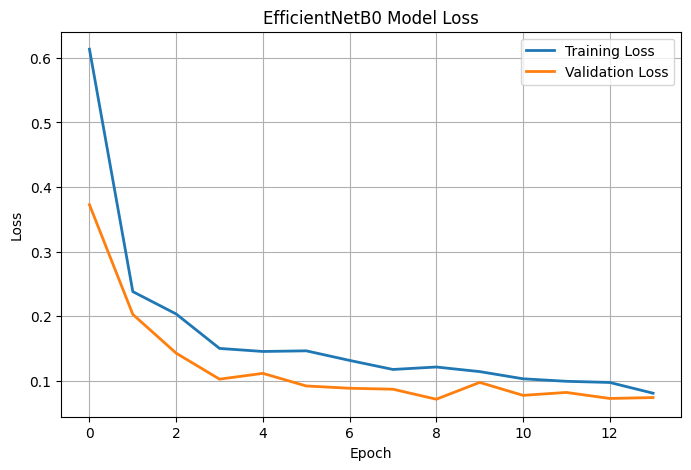

In [15]:
# ============================================
# Plot Accuracy and Loss Graph
# ============================================

import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('EfficientNetB0 Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss Graph
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('EfficientNetB0 Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

17/17 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step


<Figure size 800x800 with 0 Axes>

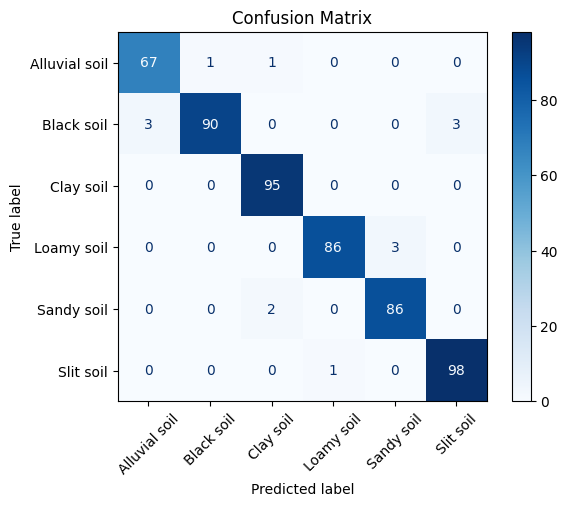

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# True labels
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

# Predictions
y_pred = np.argmax(model.predict(test_dataset), axis=1)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

In [18]:
# ============================================
# Classification Report
# ============================================

from sklearn.metrics import classification_report
import pandas as pd

# Generate Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

# Convert to DataFrame
report_df = pd.DataFrame(report).transpose()

# Display report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Display as table
report_df

               precision    recall  f1-score   support

Alluvial soil       0.96      0.97      0.96        69
   Black soil       0.99      0.94      0.96        96
    Clay soil       0.97      1.00      0.98        95
   Loamy soil       0.99      0.97      0.98        89
   Sandy soil       0.97      0.98      0.97        88
    Slit soil       0.97      0.99      0.98        99

     accuracy                           0.97       536
    macro avg       0.97      0.97      0.97       536
 weighted avg       0.97      0.97      0.97       536



,precision,recall,f1-score,support
Alluvial soil,0.957143,0.971014,0.964029,69.000000
Black soil,0.989011,0.937500,0.962567,96.000000
Clay soil,0.969388,1.000000,0.984456,95.000000
Loamy soil,0.988506,0.966292,0.977273,89.000000
Sandy soil,0.966292,0.977273,0.971751,88.000000
Slit soil,0.970297,0.989899,0.980000,99.000000
accuracy,0.973881,0.973881,0.973881,0.973881
macro avg,0.973439,0.973663,0.973346,536.000000
weighted avg,0.974160,0.973881,0.973804,536.000000


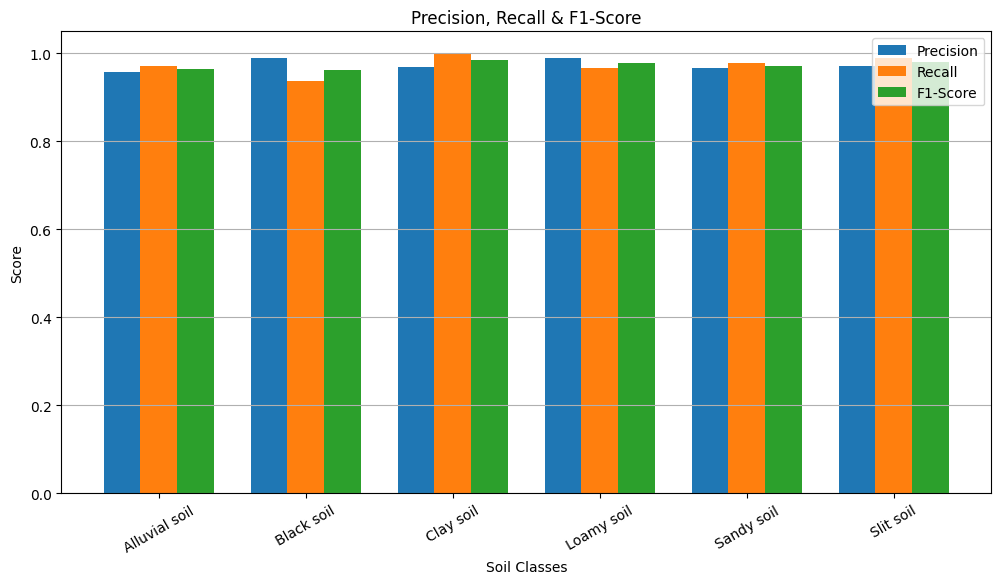

In [19]:
# ============================================
# Precision, Recall & F1-Score Graph
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# Remove summary rows
metrics_df = report_df.iloc[:-3]

precision = metrics_df["precision"]
recall = metrics_df["recall"]
f1_score = metrics_df["f1-score"]

x = np.arange(len(metrics_df))
width = 0.25

plt.figure(figsize=(12,6))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1_score, width, label="F1-Score")

plt.xticks(x, metrics_df.index, rotation=30)
plt.xlabel("Soil Classes")
plt.ylabel("Score")
plt.title("Precision, Recall & F1-Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y")

plt.show()

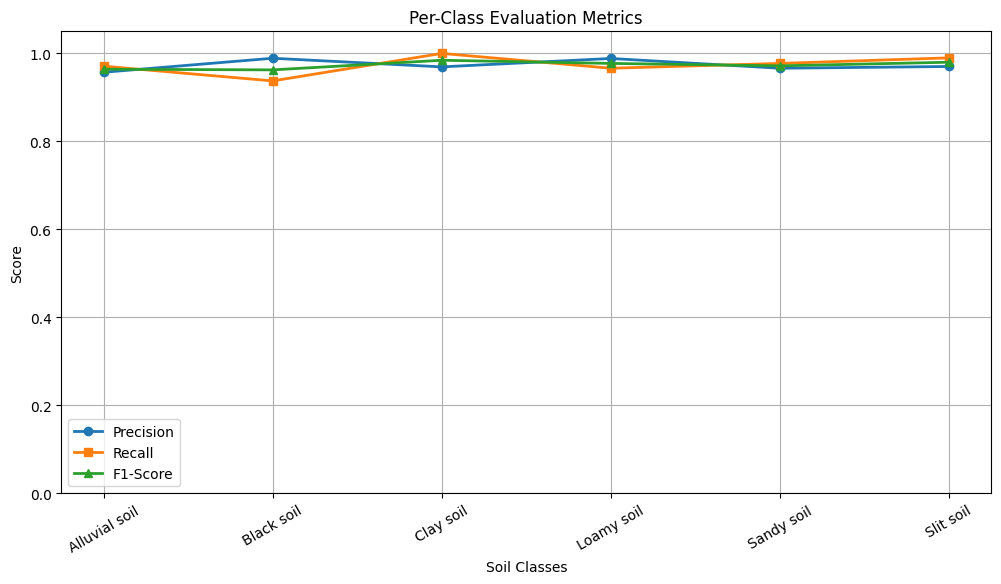

In [20]:
# ============================================
# Per-Class Evaluation Metrics
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# Remove summary rows
metrics_df = report_df.iloc[:-3]

classes = metrics_df.index
precision = metrics_df["precision"]
recall = metrics_df["recall"]
f1_score = metrics_df["f1-score"]

plt.figure(figsize=(12,6))

plt.plot(classes, precision, marker='o', linewidth=2, label='Precision')
plt.plot(classes, recall, marker='s', linewidth=2, label='Recall')
plt.plot(classes, f1_score, marker='^', linewidth=2, label='F1-Score')

plt.title("Per-Class Evaluation Metrics")
plt.xlabel("Soil Classes")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.xticks(rotation=30)

plt.show()

Saving 0538.jpg to 0538.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step


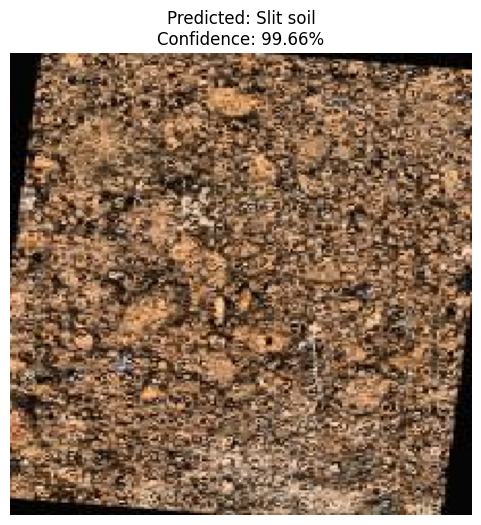

Predicted Soil Type: Slit soil
Confidence Score: 99.66%

Prediction Probabilities:
Alluvial soil  : 0.13%
Black soil     : 0.08%
Clay soil      : 0.00%
Loamy soil     : 0.07%
Sandy soil     : 0.06%
Slit soil      : 99.66%


In [22]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250114_163432_jpg.rf.66da9e892a964e0921cb856e6aacd49f.jpg to IMG_20250114_163432_jpg.rf.66da9e892a964e0921cb856e6aacd49f.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step


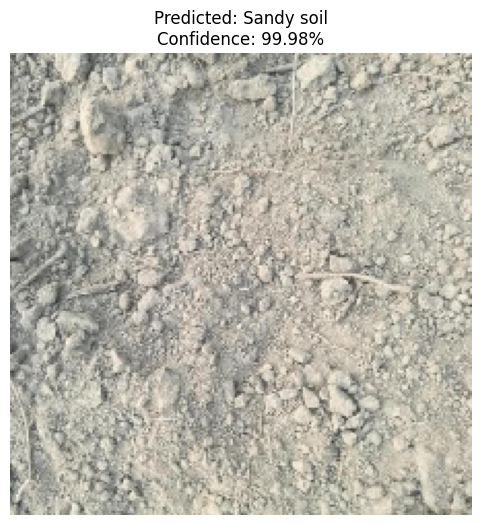

Predicted Soil Type: Sandy soil
Confidence Score: 99.98%

Prediction Probabilities:
Alluvial soil  : 0.01%
Black soil     : 0.00%
Clay soil      : 0.01%
Loamy soil     : 0.01%
Sandy soil     : 99.98%
Slit soil      : 0.00%


In [23]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250110_160418_jpg.rf.afa96b6621270b169e545a36d1499fab.jpg to IMG_20250110_160418_jpg.rf.afa96b6621270b169e545a36d1499fab.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step


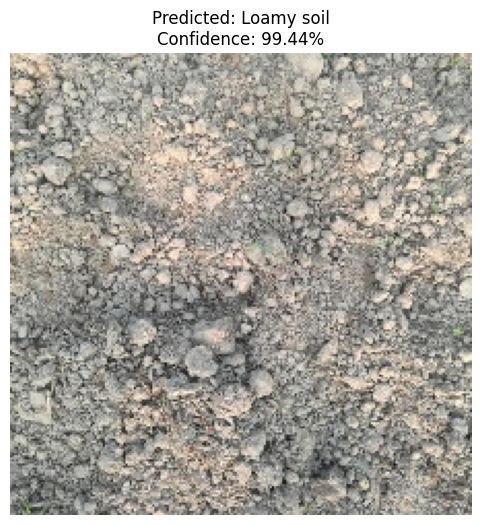

Predicted Soil Type: Loamy soil
Confidence Score: 99.44%

Prediction Probabilities:
Alluvial soil  : 0.00%
Black soil     : 0.00%
Clay soil      : 0.00%
Loamy soil     : 99.44%
Sandy soil     : 0.47%
Slit soil      : 0.09%


In [24]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250115_131048_jpg.rf.65a666cc3b1956dc683324cc75dcb9a2.jpg to IMG_20250115_131048_jpg.rf.65a666cc3b1956dc683324cc75dcb9a2.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step


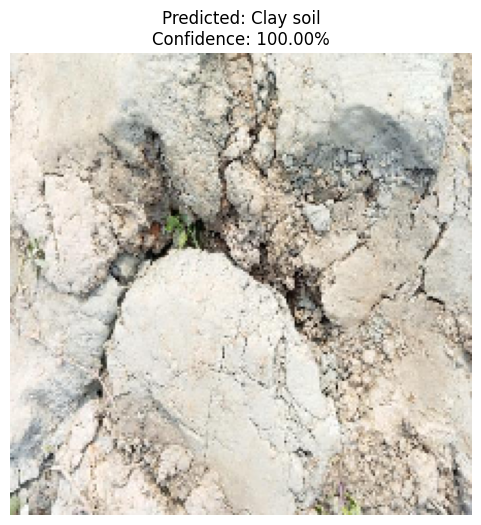

Predicted Soil Type: Clay soil
Confidence Score: 100.00%

Prediction Probabilities:
Alluvial soil  : 0.00%
Black soil     : 0.00%
Clay soil      : 100.00%
Loamy soil     : 0.00%
Sandy soil     : 0.00%
Slit soil      : 0.00%


In [25]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving ginkgo-leaf-on-ground-black-260nw-380461555_jpg.rf.e2af2001c5cf7f9e74ab246c56423fcd.jpg to ginkgo-leaf-on-ground-black-260nw-380461555_jpg.rf.e2af2001c5cf7f9e74ab246c56423fcd.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


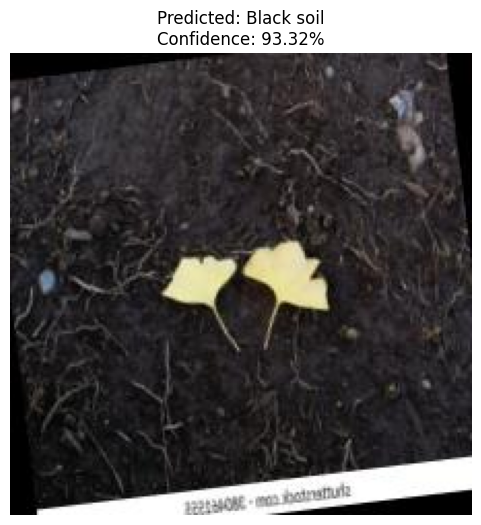

Predicted Soil Type: Black soil
Confidence Score: 93.32%

Prediction Probabilities:
Alluvial soil  : 6.45%
Black soil     : 93.32%
Clay soil      : 0.15%
Loamy soil     : 0.07%
Sandy soil     : 0.01%
Slit soil      : 0.01%


In [26]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving alluvial_574.jpg to alluvial_574.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


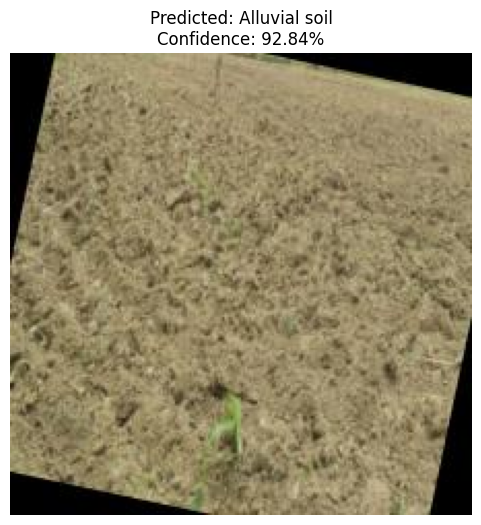

Predicted Soil Type: Alluvial soil
Confidence Score: 92.84%

Prediction Probabilities:
Alluvial soil  : 92.84%
Black soil     : 1.61%
Clay soil      : 0.28%
Loamy soil     : 0.00%
Sandy soil     : 5.19%
Slit soil      : 0.08%


In [27]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving 0580.jpg to 0580.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


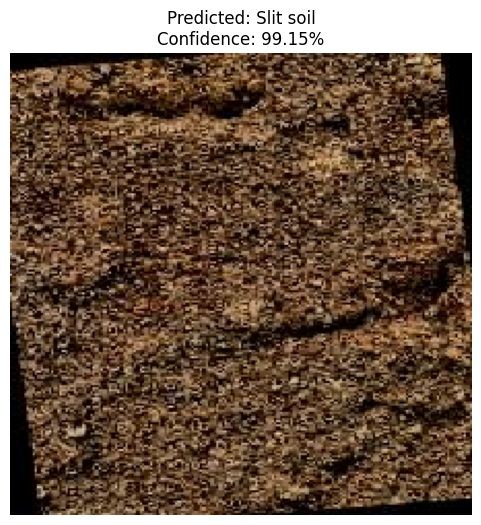

Predicted Soil Type: Slit soil
Confidence Score: 99.15%

Prediction Probabilities:
Alluvial soil  : 0.00%
Black soil     : 0.85%
Clay soil      : 0.00%
Loamy soil     : 0.00%
Sandy soil     : 0.00%
Slit soil      : 99.15%


In [28]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250114_163022_jpg.rf.5f548500dd3d234eb2ab80abfdd22cdc.jpg to IMG_20250114_163022_jpg.rf.5f548500dd3d234eb2ab80abfdd22cdc.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step


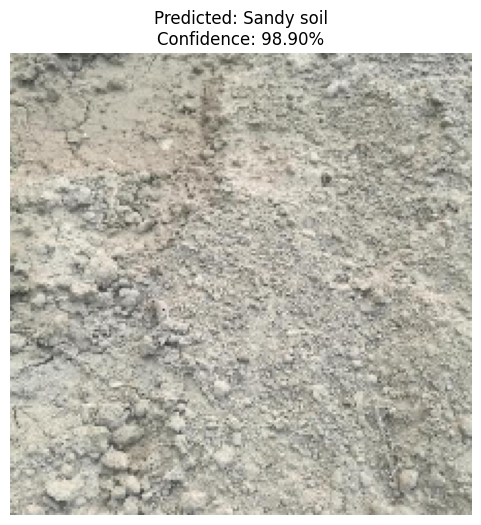

Predicted Soil Type: Sandy soil
Confidence Score: 98.90%

Prediction Probabilities:
Alluvial soil  : 0.43%
Black soil     : 0.03%
Clay soil      : 0.12%
Loamy soil     : 0.19%
Sandy soil     : 98.90%
Slit soil      : 0.34%


In [29]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250110_155805_jpg.rf.59b926b7b395a59d90019c395a101862.jpg to IMG_20250110_155805_jpg.rf.59b926b7b395a59d90019c395a101862.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


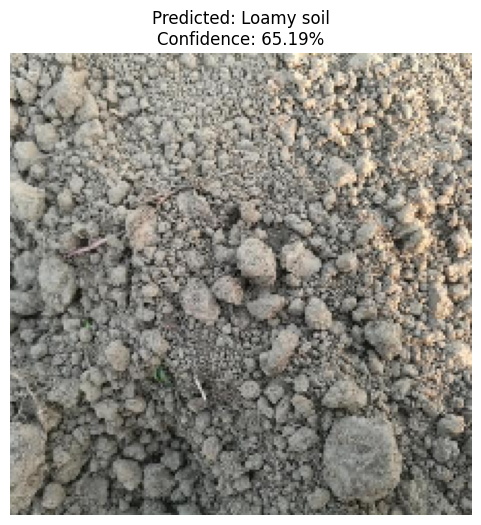

Predicted Soil Type: Loamy soil
Confidence Score: 65.19%

Prediction Probabilities:
Alluvial soil  : 0.01%
Black soil     : 0.00%
Clay soil      : 0.03%
Loamy soil     : 65.19%
Sandy soil     : 34.06%
Slit soil      : 0.71%


In [30]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving IMG_20250113_141311_2_jpg.rf.01f33e697842ce79f0ae3c59cb946536.jpg to IMG_20250113_141311_2_jpg.rf.01f33e697842ce79f0ae3c59cb946536.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


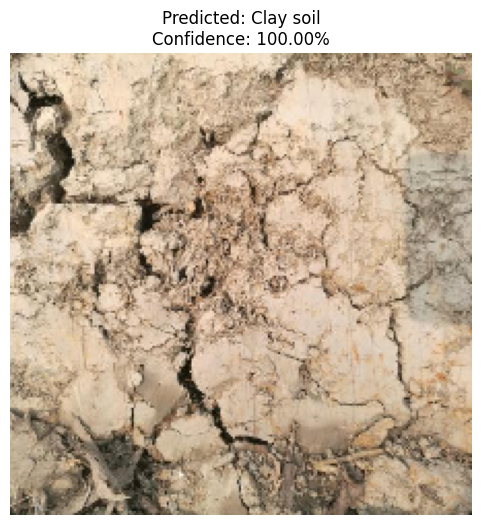

Predicted Soil Type: Clay soil
Confidence Score: 100.00%

Prediction Probabilities:
Alluvial soil  : 0.00%
Black soil     : 0.00%
Clay soil      : 100.00%
Loamy soil     : 0.00%
Sandy soil     : 0.00%
Slit soil      : 0.00%


In [31]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving soil-260nw-41206792_jpg.rf.103557b5de4dfd0b0e29803387f14309.jpg to soil-260nw-41206792_jpg.rf.103557b5de4dfd0b0e29803387f14309.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step


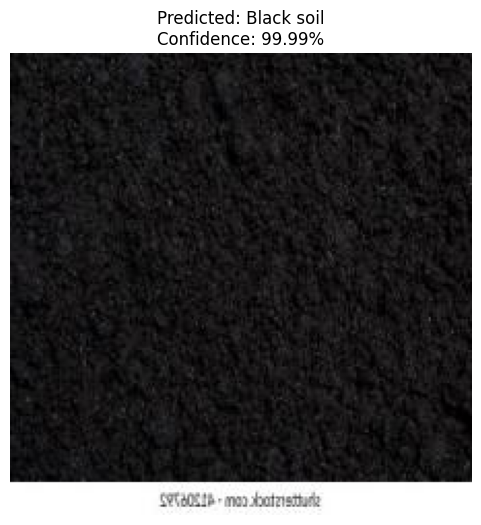

Predicted Soil Type: Black soil
Confidence Score: 99.99%

Prediction Probabilities:
Alluvial soil  : 0.01%
Black soil     : 99.99%
Clay soil      : 0.00%
Loamy soil     : 0.00%
Sandy soil     : 0.00%
Slit soil      : 0.00%


In [32]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving alluvial_598.jpg to alluvial_598.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


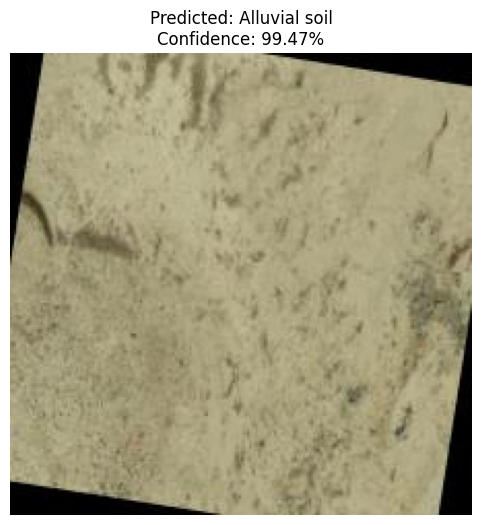

Predicted Soil Type: Alluvial soil
Confidence Score: 99.47%

Prediction Probabilities:
Alluvial soil  : 99.47%
Black soil     : 0.04%
Clay soil      : 0.48%
Loamy soil     : 0.00%
Sandy soil     : 0.00%
Slit soil      : 0.00%


In [33]:
# ============================================
# Predict New Soil Image
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from tensorflow.keras.models import load_model

model = load_model('/content/drive/MyDrive/best_efficientnetb0_soil_model.keras')

print("✅ Model Loaded Successfully!")

✅ Model Loaded Successfully!


Saving 0471.jpg to 0471.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


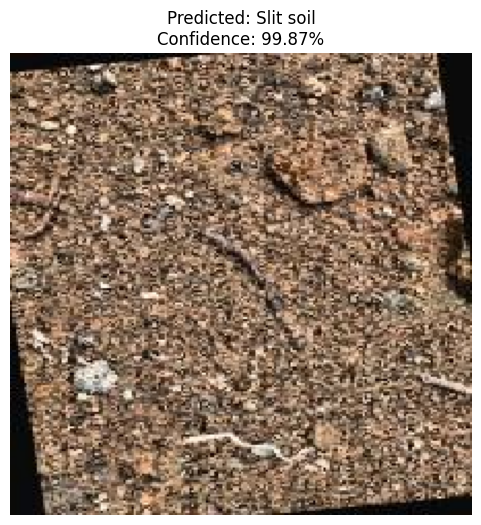

Predicted Soil Type: Slit soil
Confidence Score: 99.87%

Prediction Probabilities:
Alluvial soil  : 0.02%
Black soil     : 0.01%
Clay soil      : 0.00%
Loamy soil     : 0.02%
Sandy soil     : 0.08%
Slit soil      : 99.87%


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")

Saving 0199.jpg to 0199.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step


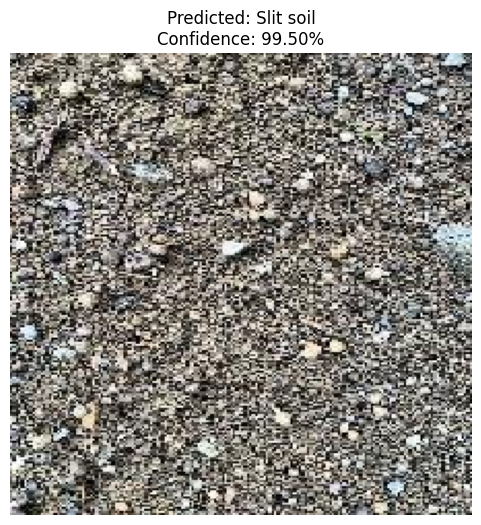

Predicted Soil Type: Slit soil
Confidence Score: 99.50%

Prediction Probabilities:
Alluvial soil  : 0.00%
Black soil     : 0.00%
Clay soil      : 0.00%
Loamy soil     : 0.46%
Sandy soil     : 0.04%
Slit soil      : 99.50%


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded file name
img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Class names
class_names = [
    "Alluvial soil",
    "Black soil",
    "Clay soil",
    "Loamy soil",
    "Sandy soil",
    "Slit soil"
]

# Predicted class
predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

# Display uploaded image
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

# Print prediction
print("Predicted Soil Type:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Display probability of each class
print("\nPrediction Probabilities:")
for cls, prob in zip(class_names, prediction[0]):
    print(f"{cls:15}: {prob*100:.2f}%")